In [350]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import numpy as np 

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer 
from sklearn.preprocessing import OneHotEncoder ,StandardScaler , MinMaxScaler

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import RobustScaler

In [351]:
df=pd.read_csv("transactions_TP2.csv")

In [352]:
df.head()

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


In [353]:
df.shape

(3045, 12)

In [354]:
df.dtypes

id_operation            str
id_client               str
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                   str
appareil                str
region                  str
international           str
resultat_enquete        str
fraude                int64
dtype: object

In [355]:
pnull = pd.DataFrame(df.isna().mean()*100)
pnull = pnull.sort_values(by=0, ascending=False)
print(pnull.round(2))

                     0
canal             5.22
anciennete_mois   4.50
appareil          4.01
montant_dh        3.61
region            3.38
nb_ops_24h        1.74
id_operation      0.00
id_client         0.00
heure             0.00
international     0.00
resultat_enquete  0.00
fraude            0.00


In [356]:
print(df.duplicated(subset=['id_operation']).sum())
df = df.drop_duplicates(subset=['id_operation'])
print(len(df))

45
3000


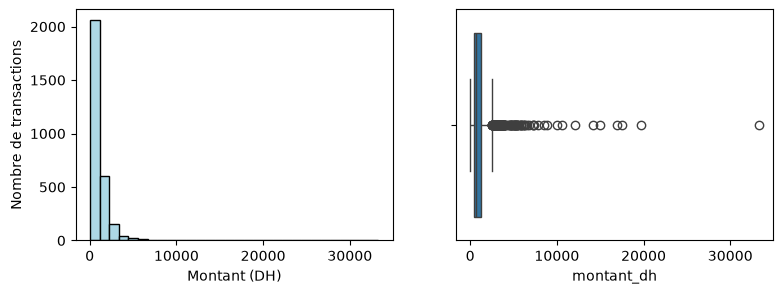

In [357]:
plt.figure(figsize=(9, 3))

plt.subplot(1, 2, 1)
plt.hist(df['montant_dh'], bins=30 , 
    edgecolor='black', color='lightblue')

plt.xlabel("Montant (DH)")
plt.ylabel("Nombre de transactions")

plt.subplot(1, 2, 2)
sns.boxplot(x=df['montant_dh'])

plt.show()

In [358]:
print((df['fraude'] == 1).mean()*100)

8.6


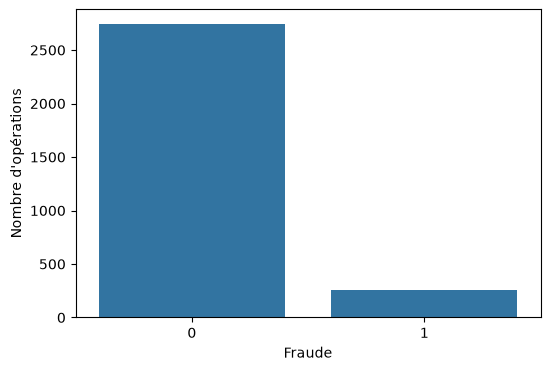

In [359]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='fraude')

plt.xlabel("Fraude")
plt.ylabel("Nombre d'opérations")

plt.show()

In [360]:
X = df.drop(columns=[
    'id_operation',
    'id_client',
    'resultat_enquete',
    'fraude'
])
y = df['fraude']

In [361]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.20, stratify=y, random_state=42)

In [362]:
print("Pourcentage de fraude dans Train :")
print(((y_train == 1).mean() * 100).round(2))

print("Pourcentage de fraude dans Test :")
print(((y_test == 1).mean() * 100).round(2))

Pourcentage de fraude dans Train :
8.58
Pourcentage de fraude dans Test :
8.67


In [363]:
num_cols = ['montant_dh', 'anciennete_mois','nb_ops_24h', 'heure']

cat_cols = ['canal', 'appareil','region', 'international']

In [364]:
num_pipe = Pipeline([
("imputer", SimpleImputer(strategy="median")),
("scaler", StandardScaler())
])

X_train_num = num_pipe.fit_transform(X_train[num_cols])
X_test_num = num_pipe.transform(X_test[num_cols])

In [365]:
cat_pipe = Pipeline([
 ("imputer", SimpleImputer(strategy="most_frequent")),
 ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [366]:
prep = ColumnTransformer([
    ("numerique",num_pipe, num_cols),
    ("categorial",cat_pipe, cat_cols)
])
X_train_trs = prep.fit_transform(X_train)
X_test_trs = prep.transform(X_test)

In [367]:
print("Train :", X_train_trs.shape)
print("Test :", X_test_trs.shape)

Train : (2400, 18)
Test : (600, 18)


In [368]:
df.head()

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


In [369]:
num_pipe_robust = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

X_train_rb = num_pipe_robust.fit_transform(X_train[num_cols])
X_test_rb = num_pipe_robust.transform(X_test[num_cols])

In [370]:
print("StandardScaler:")
print(X_train_num[:, 0])

StandardScaler:
[-0.45279558 -0.36731967 -0.40885247 ...  0.32270931 -0.23341141
 -0.09545835]


In [371]:
print(X_train_num[:, 0].max())
print(X_train_num[:, 0].min())

24.29944226303708
-0.7413709584147189


In [372]:
print("Robust:")
print(X_train_rb[:, 0])

Robust:
[-0.35673954 -0.21774757 -0.28528385 ...  0.90430522  0.
  0.22432482]


In [373]:
print(X_train_rb[:, 0].max())
print(X_train_rb[:, 0].min())

39.892755220772855
-0.8259905689264498


In [374]:
print("Standard ordinaire :", np.median(X_train_num[:, 0]))
print("Standard très élevé   :", X_train_num[:, 0].max())

print("Robust ordinaire :", np.median(X_train_rb[:, 0]))
print("Robust très élevé   :", X_train_rb[:, 0].max())

Standard ordinaire : -0.23341141403208543
Standard très élevé   : 24.29944226303708
Robust ordinaire : 0.0
Robust très élevé   : 39.892755220772855


In [375]:
Q1 =  X_train['montant_dh'].quantile(0.25)
Q3 = X_train['montant_dh'].quantile(0.75)
IQR = Q3 - Q1
print(f"Q1 : {Q1:.2f} Q3: {Q3:.2f} IQR: {IQR:.2f} ")

Q1 : 393.10 Q3: 1249.88 IQR: 856.78 


In [376]:
li = Q1 - 1.5 * IQR
ls = Q3 + 1.5 * IQR
print(f"la borne inferieur : {li:.2f} la borne inferieur : {ls:.2f} ")
print("les valeurs au-dessous " ,(X_train['montant_dh'] < li).sum())
print("les valeurs au-dessus " ,(X_train['montant_dh'] > ls).sum())

cas = X_train[X_train["montant_dh"] > ls].copy()
cas["fraude"] = y_train[cas.index]

cas.sort_values(by="montant_dh", ascending=False).head()

la borne inferieur : -892.08 la borne inferieur : 2535.05 
les valeurs au-dessous  0
les valeurs au-dessus  146


,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,fraude
2660,33281.23,34.0,4.0,17,application,mobile,Autre,non,0
539,19658.42,77.0,1.0,11,application,mobile,Autre,non,0
1775,17496.64,146.0,2.0,3,site_web,mobile,Marrakech-Safi,non,0
2556,14951.95,128.0,2.0,6,application,ordinateur,Draa-Tafilalet,non,0
65,14135.85,32.0,1.0,14,application,ordinateur,Draa-Tafilalet,non,0


In [377]:
seuil = X_train.copy()
seuil.loc[seuil['montant_dh'] > ls, 'montant_dh'] = ls

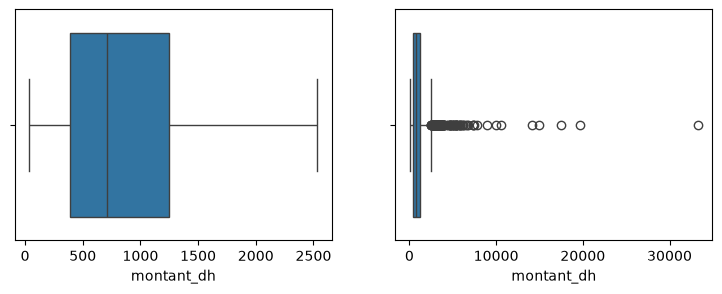

In [378]:
plt.figure(figsize=(9, 3))

plt.subplot(1, 2, 1)
sns.boxplot(x=seuil['montant_dh'])

plt.subplot(1, 2, 2)
sns.boxplot(x=X_train['montant_dh'])

plt.show()

In [379]:
a = X_train[['montant_dh']]
b = X_test[["montant_dh"]]

In [380]:
sc = MinMaxScaler()

train_minmax = sc.fit_transform(a)
test_minmax = sc.transform(b)

In [381]:
st = StandardScaler()

train_standard = st.fit_transform(a)
test_standard = st.transform(b)

In [382]:
rb = RobustScaler()

train_robust = rb.fit_transform(a)
test_robust = rb.transform(b)

In [383]:
montants = pd.DataFrame({
    "montant_dh": [       
        a['montant_dh'].quantile(0.25),
        a['montant_dh'].median(),
        a['montant_dh'].quantile(0.75),
        a['montant_dh'].max()
    ]
}, index=["Q1", "Médiane", "Q3", "Très élevé"])

montants["MinMax"] = sc.transform(montants[["montant_dh"]])
montants["Standard"] = st.transform(montants[["montant_dh"]])
montants["Robust"] = rb.transform(montants[["montant_dh"]])

print(montants.round(3))

            montant_dh  MinMax  Standard  Robust
Q1             393.095   0.011    -0.473  -0.371
Médiane        710.790   0.020    -0.238   0.000
Q3            1249.878   0.037     0.161   0.629
Très élevé   33281.230   1.000    23.866  38.015


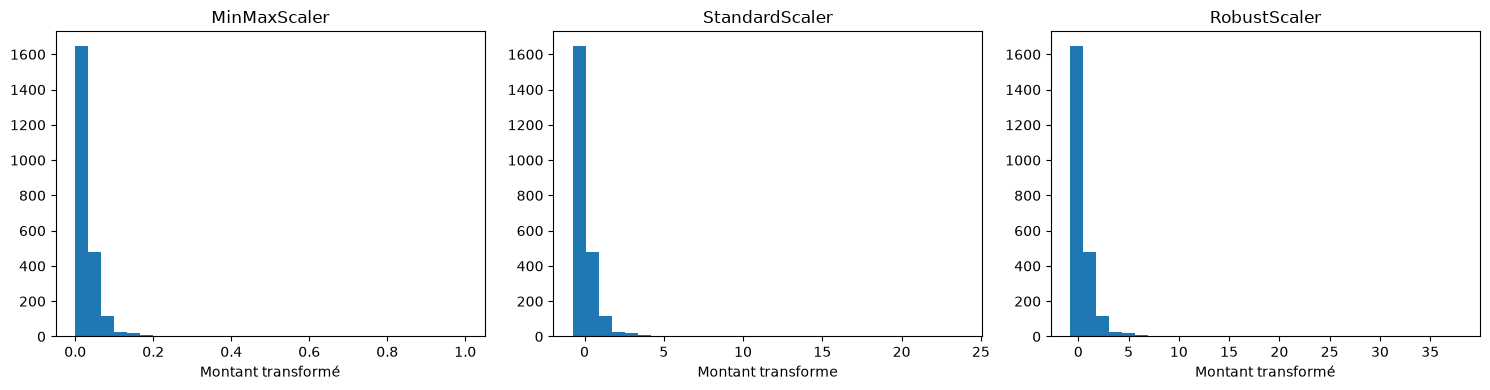

In [384]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.hist(sc.transform(a[['montant_dh']]), bins=30)
plt.title("MinMaxScaler")
plt.xlabel("Montant transformé")

plt.subplot(1, 3, 2)
plt.hist(st.transform(a[['montant_dh']]), bins=30)
plt.title("StandardScaler")
plt.xlabel("Montant transforme")

plt.subplot(1, 3, 3)
plt.hist(rb.transform(a[['montant_dh']]), bins=30)
plt.title("RobustScaler")
plt.xlabel("Montant transformé")

plt.tight_layout()
plt.show()

In [385]:
print("nombres des normal :" , y_train.value_counts()[0])
print("nombres des fraudes :" , y_train.value_counts()[1])
rapport = y_train.value_counts()[0] / y_train.value_counts()[1]

print("rapport de fraude " , rapport)

nombres des normal : 2194
nombres des fraudes : 206
rapport de fraude  10.650485436893204


In [386]:
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

print("Avant :")
print(y_train.value_counts())

ros = RandomOverSampler(random_state=42)
X_over, y_over = ros.fit_resample(X_train, y_train)

print("Après :")
print(y_over.value_counts())

Avant :
fraude
0    2194
1     206
Name: count, dtype: int64
Après :
fraude
0    2194
1    2194
Name: count, dtype: int64


In [387]:
print("Avant :")
print(y_train.value_counts())

rus = RandomUnderSampler(random_state=42)
X_under, y_under = rus.fit_resample(X_train, y_train)

print("Après :")
print(y_under.value_counts())

print("Lignes conservées :", len(X_under))
print("Lignes supprimées :", len(X_train) - len(X_under))

Avant :
fraude
0    2194
1     206
Name: count, dtype: int64
Après :
fraude
0    206
1    206
Name: count, dtype: int64
Lignes conservées : 412
Lignes supprimées : 1988


In [388]:
from imblearn.over_sampling import SMOTE

X = pd.DataFrame({
    'montant_dh': [100, 200, 300, 150, 250],
    'ancienne_mois': [10, 20, 30, 15, 25]
})

y = [0, 0, 0, 1, 1]

smote = SMOTE(random_state=42, k_neighbors=1)
X_resampled, y_resampled = smote.fit_resample(X, y)

print("Avant SMOTE :")
print(pd.Series(y).value_counts())

print("\nAprès SMOTE :")
print(pd.Series(y_resampled).value_counts())

print("\nNouvelles observations :")
print(X_resampled.iloc[5:])

Avant SMOTE :
0    3
1    2
Name: count, dtype: int64

Après SMOTE :
0    3
1    3
Name: count, dtype: int64

Nouvelles observations :
   montant_dh  ancienne_mois
5         229             22


In [389]:

tab = pd.DataFrame({
    "Avant":             y_train.value_counts(),
    "Sur-échantillonnage": y_over.value_counts(),
    "Sous-échantillonnage": y_under.value_counts()
})
tab.loc["Total"] = tab.sum()
print(tab)

print("Vérification :", y_test.value_counts())   

        Avant  Sur-échantillonnage  Sous-échantillonnage
fraude                                                  
0        2194                 2194                   206
1         206                 2194                   206
Total    2400                 4388                   412
Vérification : fraude
0    548
1     52
Name: count, dtype: int64


In [390]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])


cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


preprocess = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

In [391]:
xt = preprocess.fit_transform(X_train)
xts = preprocess.transform(X_test)

print("X_train :", xt.shape)
print("X_test  :", xt.shape)

print("NaN dans X_train :", np.isnan(xt).sum())
print("NaN dans X_test  :", np.isnan(xt).sum())

X_train : (2400, 18)
X_test  : (2400, 18)
NaN dans X_train : 0
NaN dans X_test  : 0


In [392]:
nouvelle = X_test.iloc[[0]].copy()
nouvelle["canal"] = "crypto"        

resultat = preprocess.transform(nouvelle)
       
colonnes = preprocess.get_feature_names_out()

resultat_df = pd.DataFrame(resultat, columns=colonnes)

print(resultat_df.round(3).T)

                                   0
num__montant_dh                0.104
num__anciennete_mois          -0.298
num__nb_ops_24h               -1.000
num__heure                     0.308
cat__canal_agence              0.000
cat__canal_application         0.000
cat__canal_site_web            0.000
cat__canal_telephone           0.000
cat__appareil_mobile           0.000
cat__appareil_ordinateur       1.000
cat__appareil_terminal         0.000
cat__region_Autre              0.000
cat__region_Casablanca-Settat  0.000
cat__region_Draa-Tafilalet     1.000
cat__region_Marrakech-Safi     0.000
cat__region_Souss-Massa        0.000
cat__international_non         0.000
cat__international_oui         1.000


In [393]:
import joblib
joblib.dump(preprocess, "preprocess.joblib")

preprocess2 = joblib.load("preprocess.joblib")

echantillon = X_test.head(5)
print("est ce que il donne les meme valeurs ? ",np.allclose(preprocess.transform(echantillon),
                  preprocess2.transform(echantillon)))     

est ce que il donne les meme valeurs ?  True


In [394]:
df_moyenne = X_train.copy()
df_mediane = X_train.copy()

moyenne = df_moyenne["montant_dh"].mean()
mediane = df_mediane["montant_dh"].median()

df_moyenne["montant_dh"] = df_moyenne["montant_dh"].fillna(moyenne)

df_mediane["montant_dh"] = df_mediane["montant_dh"].fillna(mediane)

print("Moyenne :", moyenne)
print("Médiane :", mediane)



Moyenne : 1032.467776816609
Médiane : 710.79
